In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# EDA WITH CLEANED DATA

In [36]:
df = pd.read_csv('D:/Project 3 - Marketing Campaign Analysis/Marketing Campaign/cleaned_data.csv')

In [37]:
df.describe()

,Duration,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Engagement_Score,Profit/Loss_flag
count,143376.000000,143376.000000,143376.000000,143376.000000,143376.000000,1.433760e+05,143376.000000,143376.000000,143376.000000,143376.000000
mean,17.474138,55079.187765,4635.247789,1818.858554,997.713878,4.854415e+05,309.665777,2.243097,13.753131,0.759604
std,7.310671,25340.663197,3082.821670,1300.517870,762.741541,3.966826e+05,268.017601,2.865587,6.174497,0.427325
min,5.000000,10001.000000,207.000000,48.000000,17.000000,3.895000e+03,8.180000,-0.990000,2.560000,0.000000
25%,11.000000,33718.750000,2183.000000,808.000000,400.000000,1.772672e+05,106.700000,0.040000,8.630000,1.000000
50%,17.000000,55079.000000,3898.000000,1475.000000,775.000000,3.588000e+05,209.030000,1.230000,13.753131,1.000000
75%,24.000000,76478.250000,6503.000000,2523.000000,1403.000000,6.855810e+05,429.260000,3.580000,18.520000,1.000000
max,30.000000,100000.000000,12983.000000,5095.500000,2907.500000,1.448052e+06,913.100000,8.890000,30.990000,1.000000


- The average campaign gets about **55,000 impressions**, **4,600 clicks**, **1,800 leads** and **1,000 conversions**.
- The average revenue is about **Rs.4.85 lakh**, but the middle value (median) is only **Rs.3.59 lakh**. When the average is higher than the middle, a few very big campaigns are pulling it up.
- Acquisition cost follows the same pattern: the average is about Rs.310 per conversion, the middle is about Rs.209.
- About **76% of campaigns make a profit** (the Profit/Loss flag has an average of 0.76).
- Campaigns last between **5 and 30 days**, about 17 days on average.

In [38]:
df.describe(include="str")

,Campaign_Type,Target_Audience,Channel_Used,Language,Customer_Segment,Platform
count,143376,143376,143376,143376,143376,143376
unique,6,6,157,5,6,3
top,Influencer,Youth,Email,Hindi,Youth,Tira
freq,27372,27395,7710,34182,27470,47882


- Each category is spread almost evenly. For example, every campaign type has about 27,000 campaigns, so no group dominates the data.
- "Unknown" is a separate group. It holds campaigns where the type or audience was missing in the original data.
- Tira has the most campaigns (47,882), Hindi is the most common language, and Youth is the most common audience and segment.
- Campaigns use many different channel combinations (157 in total), such as "Email" alone or "YouTube, Facebook, Google" together.

In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 143376 entries, 0 to 143375
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Campaign_Type     143376 non-null  str    
 1   Target_Audience   143376 non-null  str    
 2   Duration          143376 non-null  int64  
 3   Channel_Used      143376 non-null  str    
 4   Impressions       143376 non-null  int64  
 5   Clicks            143376 non-null  int64  
 6   Leads             143376 non-null  float64
 7   Conversions       143376 non-null  float64
 8   Revenue           143376 non-null  float64
 9   Acquisition_Cost  143376 non-null  float64
 10  ROI               143376 non-null  float64
 11  Language          143376 non-null  str    
 12  Engagement_Score  143376 non-null  float64
 13  Customer_Segment  143376 non-null  str    
 14  Platform          143376 non-null  str    
 15  Profit/Loss_flag  143376 non-null  int64  
dtypes: float64(6), int64(4), str(6)

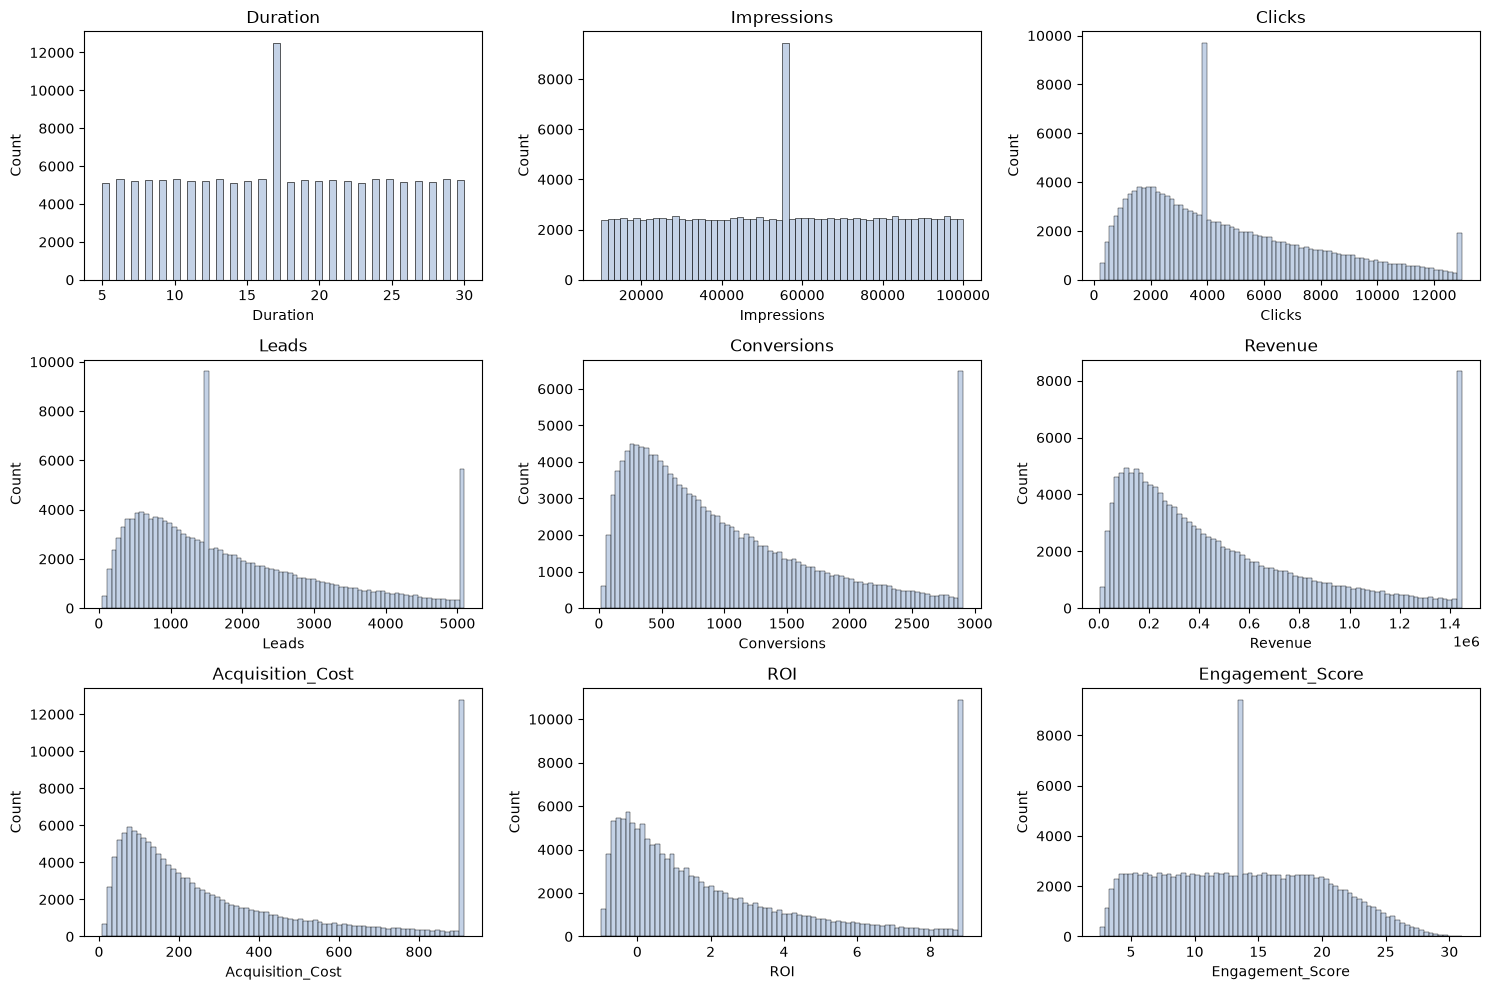

In [40]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for ax, col in zip(axes.ravel(), df.select_dtypes(include="number").columns):
    sns.histplot(x=df[col], ax=ax, color='lightsteelblue')
    ax.set_title(col)

plt.tight_layout()
plt.show()

- **Duration, Impressions and Engagement Score** are spread fairly evenly. Campaigns are found everywhere in their range.
- **Clicks, Leads, Conversions, Revenue, Acquisition Cost and ROI** are bunched on the left and have a long tail to the right. This means most campaigns are small or average, and only a few are very big.
- **The tall bar in the middle** (for example at 17 days, or about 55,000 impressions) is not real campaigns. It comes from filling in missing values with the average or middle value.
- **The tall bar at the far right** (for example Revenue near Rs.14.5 lakh) comes from capping very large values at a limit.

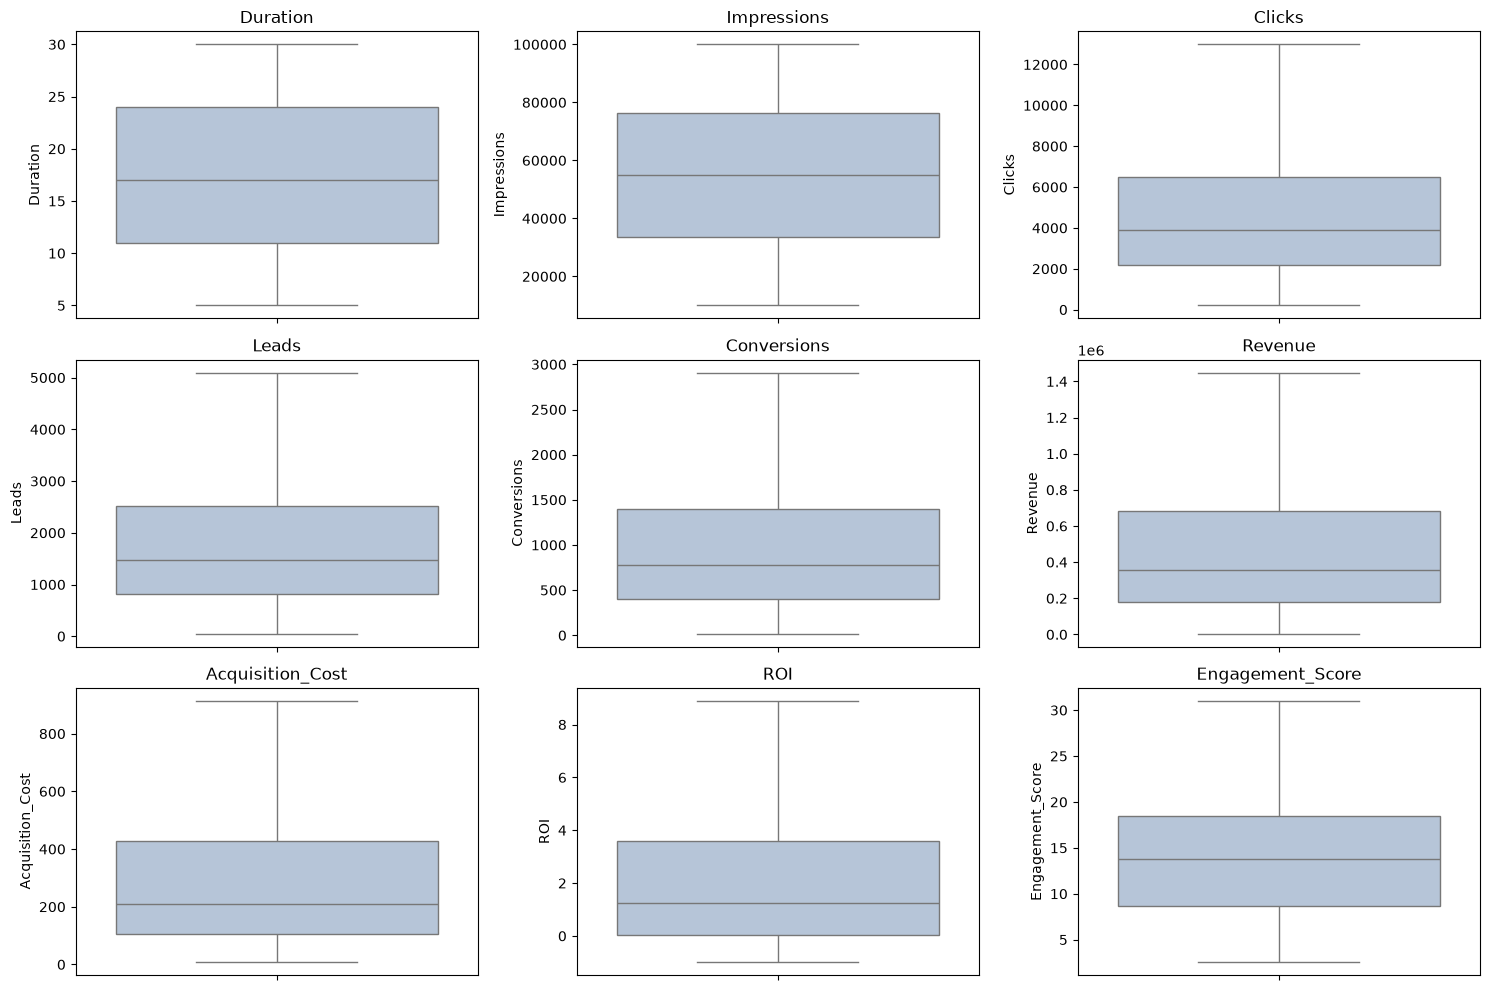

In [41]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for ax, col in zip(axes.ravel(), df.select_dtypes(include="number").columns):
    sns.boxplot(y=df[col], ax=ax, color='lightsteelblue')
    ax.set_title(col)

plt.tight_layout()
plt.show()

- None of the boxes show dots outside the whiskers. That is because extreme values were capped earlier, so the data is now cleaner.
- For Clicks, Leads, Conversions, Revenue, Acquisition Cost and ROI, the middle line sits low in the box and the upper whisker is long. This again shows many small campaigns and a few big ones.
- Duration, Impressions and Engagement Score look balanced, with the middle line near the centre.

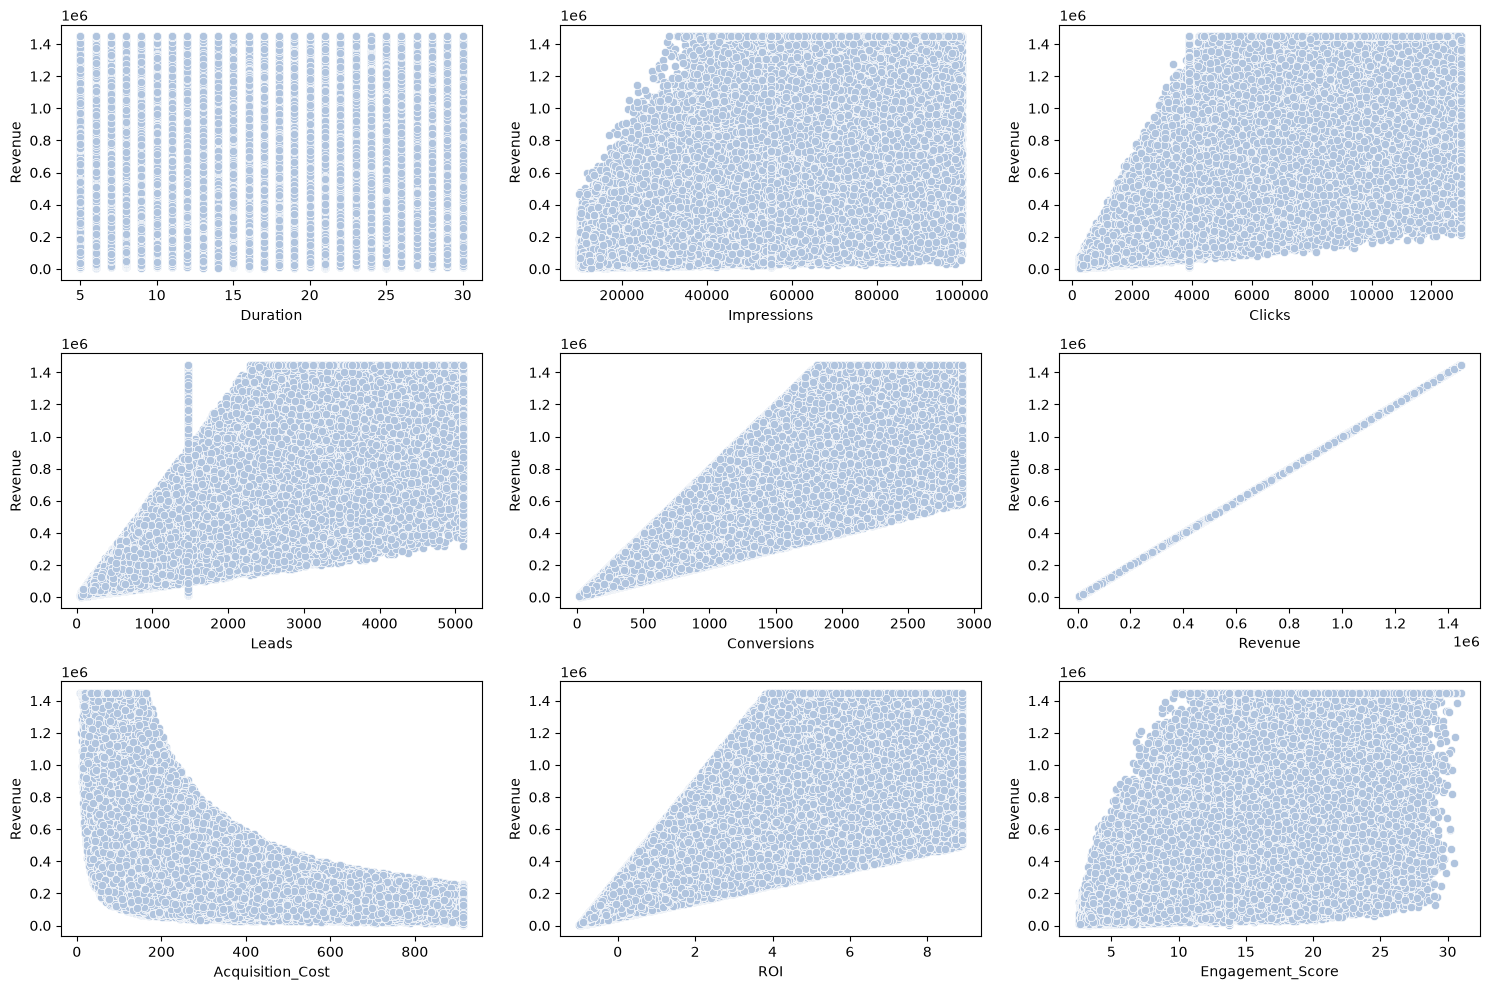

In [42]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for ax, col in zip(axes.ravel(), df.select_dtypes(include="number").columns):
    sns.scatterplot(x=df[col], y= df['Revenue'],ax=ax, color='lightsteelblue')

plt.tight_layout()
plt.show()

- **Conversions, Leads and Clicks:** Revenue goes up as these go up. Conversions shows the cleanest upward pattern.
- **Impressions:** A weaker link. A campaign with many impressions can still earn little.
- **Acquisition Cost:** The pattern curves downward. Cheap acquisition can lead to very high revenue, but once cost goes above about Rs.400 per conversion, revenue stays low.
- **Engagement Score:** Revenue tends to be higher when engagement is higher.
- **Duration:** No pattern at all. Running a campaign longer does not mean more revenue.
- The flat line at the top (Rs.14.5 lakh) comes from capping the largest values.

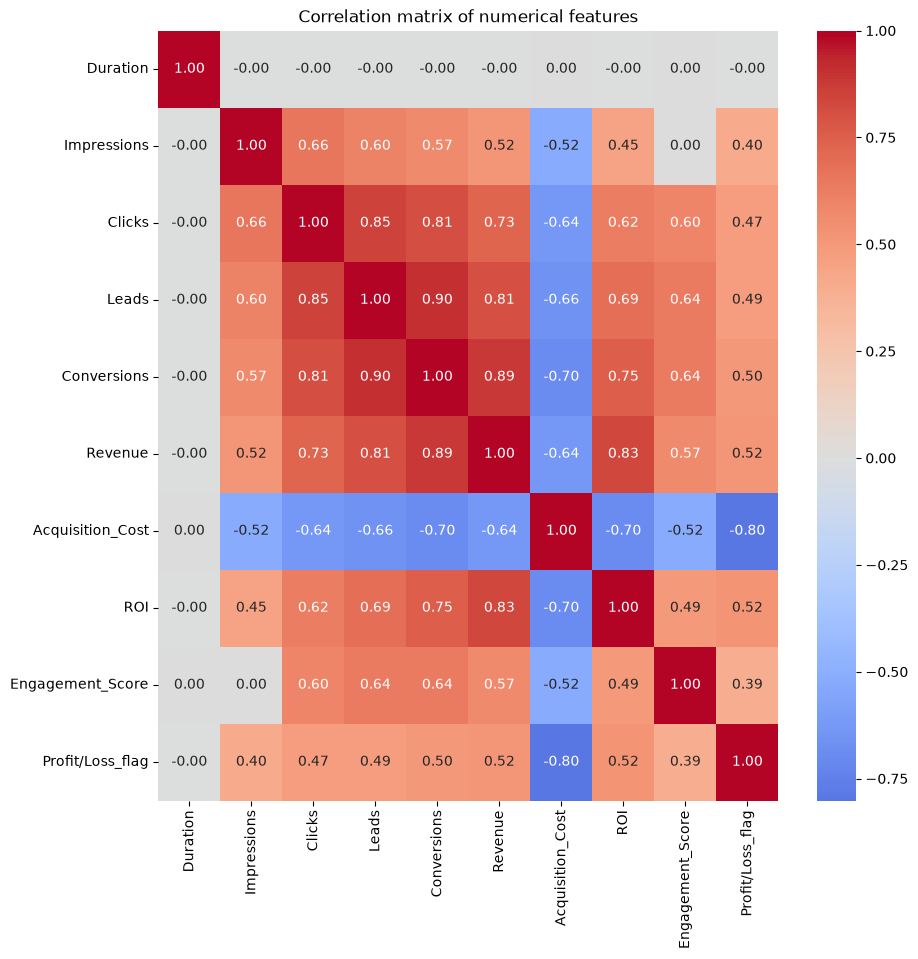

In [43]:
corr_cleaned = df.select_dtypes(include="number").corr()
corr_cleaned.round(2)

plt.figure(figsize=(10, 10))
sns.heatmap(corr_cleaned, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix of numerical features')
plt.show()

In [44]:
corr_cleaned
corr_cleaned.round(2)

,Duration,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Engagement_Score,Profit/Loss_flag
Duration,1.0,-0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00
Impressions,-0.0,1.00,0.66,0.60,0.57,0.52,-0.52,0.45,0.00,0.40
Clicks,-0.0,0.66,1.00,0.85,0.81,0.73,-0.64,0.62,0.60,0.47
Leads,-0.0,0.60,0.85,1.00,0.90,0.81,-0.66,0.69,0.64,0.49
Conversions,-0.0,0.57,0.81,0.90,1.00,0.89,-0.70,0.75,0.64,0.50
Revenue,-0.0,0.52,0.73,0.81,0.89,1.00,-0.64,0.83,0.57,0.52
Acquisition_Cost,0.0,-0.52,-0.64,-0.66,-0.70,-0.64,1.00,-0.70,-0.52,-0.80
ROI,-0.0,0.45,0.62,0.69,0.75,0.83,-0.70,1.00,0.49,0.52
Engagement_Score,0.0,0.00,0.60,0.64,0.64,0.57,-0.52,0.49,1.00,0.39
Profit/Loss_flag,-0.0,0.40,0.47,0.49,0.50,0.52,-0.80,0.52,0.39,1.00


- **Revenue** is most strongly linked to **Conversions (0.89)**, **ROI (0.83)** and **Leads (0.81)**, then Clicks (0.73).
- **Acquisition Cost is linked negatively** to Revenue (-0.64) and ROI (-0.70). Higher cost per conversion means lower returns.
- **Profit or loss** is linked most strongly to **Acquisition Cost (-0.80)**. Cost per conversion is the single biggest sign of whether a campaign loses money.
- **Clicks, Leads and Conversions** are strongly linked to each other (0.81 to 0.90), which makes sense because each step follows the one before.
- **Duration has no link (0.00) with anything.** How long a campaign runs does not change how it performs.

In [52]:
performance_cleaned = df.groupby('Campaign_Type').agg(
              Total_Campaigns=('Platform', 'count'),
              Total_Purchases=('Conversions', 'sum'),
              Total_Acquisition_Cost=('Acquisition_Cost', 'sum'),
              Total_Revenue=('Revenue', 'sum'),
              Average_ROI=('ROI', 'mean'),
              Average_duration=('Duration', 'mean'),
              Most_frequent_platform=('Platform', lambda x: x.value_counts().idxmax()))

performance_cleaned = performance_cleaned.T
performance_cleaned.round(2)
performance_cleaned

Campaign_Type,Email,Influencer,Paid Ads,SEO,Social Media,Unknown
Total_Campaigns,27353,27372,27234,27110,27148,7159
Total_Purchases,27307203.0,27268989.5,27232595.5,26877702.5,27230052.0,7131682.5
Total_Acquisition_Cost,8500277.3,8488342.93,8392508.33,8445435.42,8350199.41,2221877.03
Total_Revenue,13263409330.125,13246191812.875,13296574559.625,13093924494.5,13229334654.125,3471225905.875
Average_ROI,2.242932,2.224252,2.256282,2.237101,2.251545,2.256303
Average_duration,17.479947,17.433472,17.48792,17.463851,17.51827,17.426596
Most_frequent_platform,Purplle,Purplle,Tira,Tira,Purplle,Purplle


- **Paid Ads** earns the most revenue (about Rs.1,330 crore) and has the highest average ROI (2.26). **SEO** earns the least (about Rs.1,309 crore).
- The differences are very small. Average ROI is between 2.22 and 2.26 for every type, so **campaign type alone does not decide success**.
- The "Unknown" group has fewer campaigns, so it adds less revenue.

In [46]:
info_cols = ['Platform', 'Campaign_Type', 'Target_Audience', 'Channel_Used',
             'Conversions', 'Acquisition_Cost', 'Revenue', 'ROI']

def make_table(data):
    data = data[info_cols].reset_index(drop=True)
    data.index = data.index + 1
    return data

In [47]:
# Top 10 campaigns by ROI
make_table(df.nlargest(10, 'ROI'))

,Platform,Campaign_Type,Target_Audience,Channel_Used,Conversions,Acquisition_Cost,Revenue,ROI
1,Nykaa,Social Media,Working Women,YouTube,2481.0,49.62,1220652.000,8.89
2,Nykaa,SEO,College Students,YouTube,2242.0,27.28,652422.000,8.89
3,Nykaa,Influencer,Working Women,"Email, Facebook",1271.0,54.74,846486.000,8.89
4,Nykaa,SEO,Tier 2 City Customers,"YouTube, Facebook, Google",1542.0,38.20,1201218.000,8.89
5,Nykaa,SEO,Premium Shoppers,"Email, WhatsApp",2346.0,48.99,1381794.000,8.89
6,Nykaa,Social Media,Tier 2 City Customers,"Facebook, Google",779.0,69.68,555427.000,8.89
7,Nykaa,Influencer,Youth,"WhatsApp, Facebook, Instagram",2183.0,37.23,1403669.000,8.89
8,Nykaa,Paid Ads,College Students,"WhatsApp, Facebook, YouTube",2248.0,34.81,1448051.625,8.89
9,Nykaa,Email,Premium Shoppers,"Email, YouTube, Facebook",2907.5,38.16,1448051.625,8.89
10,Nykaa,Influencer,Tier 2 City Customers,"Facebook, Email, YouTube",2086.0,43.11,1410136.000,8.89


- All ten are from **Nykaa**, and all show an ROI of **8.89**, which is the limit the values were capped at. Their real ROI may be higher.
- What they share is a **low acquisition cost** (about Rs.12 to Rs.70) together with **many conversions**.

In [48]:
# Bottom 10 campaigns by ROI
make_table(df.nsmallest(10, 'ROI'))

,Platform,Campaign_Type,Target_Audience,Channel_Used,Conversions,Acquisition_Cost,Revenue,ROI
1,Tira,Email,Premium Shoppers,Email,19.0,913.1,3895.0,-0.990000
2,Tira,Influencer,Premium Shoppers,"Instagram, WhatsApp, Email",22.0,913.1,6072.0,-0.980000
3,Tira,Email,Youth,Unknown,17.0,913.1,6987.0,-0.972234
4,Nykaa,Paid Ads,Premium Shoppers,"Facebook, YouTube",27.0,913.1,6183.0,-0.970000
5,Purplle,Influencer,Tier 2 City Customers,Unknown,35.0,913.1,7350.0,-0.970000
6,Purplle,Email,College Students,Email,42.0,913.1,9072.0,-0.970000
7,Tira,Influencer,Working Women,"WhatsApp, Facebook, Instagram",36.0,913.1,9180.0,-0.970000
8,Tira,Social Media,Youth,"Email, WhatsApp, Instagram",37.0,913.1,8695.0,-0.970000
9,Tira,Paid Ads,Youth,Google,35.0,913.1,9625.0,-0.970000
10,Purplle,Influencer,College Students,"Email, Instagram",46.0,913.1,9338.0,-0.960842


- Six of ten are from **Tira**. Three are from Purplle, and one from Nykaa.
- Nearly all have the highest acquisition cost in the data (**Rs.913 per conversion**) and **very few conversions** (about 17 to 46).
- Their revenue is under Rs.10,000, so they lose almost everything they spend. Three of them target Premium Shoppers.

In [49]:
# Top 10 campaigns by Revenue
make_table(df.nlargest(10, 'Revenue'))

,Platform,Campaign_Type,Target_Audience,Channel_Used,Conversions,Acquisition_Cost,Revenue,ROI
1,Nykaa,Unknown,Unknown,YouTube,2058.0,133.98,1448051.625,4.93
2,Nykaa,Influencer,Working Women,"WhatsApp, Facebook",2907.5,60.15,1448051.625,6.81
3,Nykaa,Paid Ads,College Students,"WhatsApp, Facebook, YouTube",2248.0,34.81,1448051.625,8.89
4,Nykaa,Email,Premium Shoppers,"Email, YouTube, Facebook",2907.5,38.16,1448051.625,8.89
5,Nykaa,Paid Ads,Tier 2 City Customers,"YouTube, Instagram, Email",2135.0,121.85,1448051.625,4.79
6,Nykaa,Unknown,Premium Shoppers,"Email, Instagram",2649.0,22.58,1448051.625,8.89
7,Nykaa,SEO,Tier 2 City Customers,"Email, WhatsApp, Facebook",2907.5,12.27,1448051.625,8.89
8,Nykaa,Influencer,Premium Shoppers,"WhatsApp, YouTube, Google",2499.0,52.78,1448051.625,8.89
9,Nykaa,SEO,Premium Shoppers,"Instagram, YouTube, Google",2279.0,48.41,1448051.625,8.89
10,Nykaa,Email,Premium Shoppers,Google,2907.5,53.98,1448051.625,8.89


- All ten are from **Nykaa**, and all show the same revenue (about Rs.14.5 lakh), which is the cap.
- They have **very high conversions** (about 2,000 to 2,900).
- Their costs vary from low to medium (about Rs.12 to Rs.134 per conversion), so a big campaign can earn a lot without a very low cost.

In [50]:
# Bottom 10 campaigns by Revenue
make_table(df.nsmallest(10, 'Revenue'))

,Platform,Campaign_Type,Target_Audience,Channel_Used,Conversions,Acquisition_Cost,Revenue,ROI
1,Tira,Email,Premium Shoppers,Email,19.0,913.1,3895.0,-0.990000
2,Purplle,SEO,Premium Shoppers,"Email, WhatsApp, YouTube",29.0,913.1,6061.0,-0.950000
3,Tira,Influencer,Premium Shoppers,"Instagram, WhatsApp, Email",22.0,913.1,6072.0,-0.980000
4,Nykaa,Paid Ads,Premium Shoppers,"Facebook, YouTube",27.0,913.1,6183.0,-0.970000
5,Tira,Paid Ads,Tier 2 City Customers,Instagram,24.0,913.1,6240.0,-0.950000
6,Purplle,Email,Working Women,"YouTube, Facebook, Email",29.0,913.1,6902.0,-0.880000
7,Tira,Email,Youth,Unknown,17.0,913.1,6987.0,-0.972234
8,Tira,Social Media,College Students,"WhatsApp, Facebook, YouTube",35.0,913.1,7245.0,-0.900000
9,Purplle,Influencer,Tier 2 City Customers,Unknown,35.0,913.1,7350.0,-0.970000
10,Purplle,Email,College Students,"Facebook, Google",35.0,913.1,7455.0,-0.950000


- Five are from **Tira**, four from Purplle and one from Nykaa.
- All have a **very high acquisition cost (Rs.913)** and **very few conversions** (17 to 35).
- These campaigns are expensive and reach almost nobody, which is the worst combination.

In [51]:
num_cols = df.select_dtypes(include="number").columns


stats = pd.DataFrame({
    'Mean': df[num_cols].mean(),
    'Median': df[num_cols].median(),
    'Mode': df[num_cols].mode().iloc[0],
    'Std Dev': df[num_cols].std(),
    'Min': df[num_cols].min(),
    'Max': df[num_cols].max(),
    'Range': df[num_cols].max() - df[num_cols].min(),
    'Skewness': df[num_cols].skew()})
stats.round(2)

,Mean,Median,Mode,Std Dev,Min,Max,Range,Skewness
Duration,17.47,17.00,17.00,7.31,5.00,30.00,25.00,0.01
Impressions,55079.19,55079.00,55079.00,25340.66,10001.00,100000.00,89999.00,-0.00
Clicks,4635.25,3898.00,3898.00,3082.82,207.00,12983.00,12776.00,0.84
Leads,1818.86,1475.00,1475.00,1300.52,48.00,5095.50,5047.50,0.97
Conversions,997.71,775.00,2907.50,762.74,17.00,2907.50,2890.50,1.02
Revenue,485441.50,358800.00,1448051.62,396682.63,3895.00,1448051.62,1444156.62,1.07
Acquisition_Cost,309.67,209.03,913.10,268.02,8.18,913.10,904.92,1.13
ROI,2.24,1.23,8.89,2.87,-0.99,8.89,9.88,1.12
Engagement_Score,13.75,13.75,13.75,6.17,2.56,30.99,28.43,0.17
Profit/Loss_flag,0.76,1.00,1.00,0.43,0.00,1.00,1.00,-1.22


**Key takeaways**

1. Conversions are the strongest sign of revenue. More conversions means more revenue, and Clicks and Leads lead up to them.
2. Cost per conversion is the strongest sign of loss. Campaigns with an acquisition cost near Rs.900 almost always make a loss.
3. Campaign type, duration and channel matter very little. Their averages are almost the same, and Duration has no link to results.
4. Most campaigns are small, and a few are very large. This is why averages are higher than middle values.
5. About 3 in 4 campaigns are profitable.
6. The best and worst campaigns look different in cost and conversions: the best have low cost per conversion and high conversions, and the worst have high cost and few conversions.